In [1]:
import os
import cv2
import numpy as np

DATASET_PATH = "dataset/train"
categories = ["cats", "dogs"]

data = []
labels = []

IMG_SIZE = 64
MAX_IMAGES_PER_CLASS = 2000   # 2000 cats + 2000 dogs = 4000 image

for category in categories:
    folder = os.path.join(DATASET_PATH, category)
    label = categories.index(category)

    count = 0

    for img in os.listdir(folder):
        if count >= MAX_IMAGES_PER_CLASS:
            break

        try:
            img_path = os.path.join(folder, img)
            image = cv2.imread(img_path)
            image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
            data.append(image.flatten())
            labels.append(label)
            count += 1
        except:
            pass

data = np.array(data)
labels = np.array(labels)

print("Total Images:", len(data))

Total Images: 4000


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    data,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

X_train: (3200, 12288)
X_test : (800, 12288)


In [4]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(random_state=42, max_iter=5000)

svm_model.fit(X_train, y_train)

print("Training Completed!")

Training Completed!


C:\Users\krishna\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


In [5]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = svm_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:\n")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.54375

Classification Report:

              precision    recall  f1-score   support

           0       0.54      0.61      0.57       400
           1       0.55      0.47      0.51       400

    accuracy                           0.54       800
   macro avg       0.54      0.54      0.54       800
weighted avg       0.54      0.54      0.54       800


Confusion Matrix:

[[246 154]
 [211 189]]


In [6]:
import joblib

joblib.dump(svm_model, "cat_dog_svm_model.pkl")

print("Model Saved Successfully!")

Model Saved Successfully!


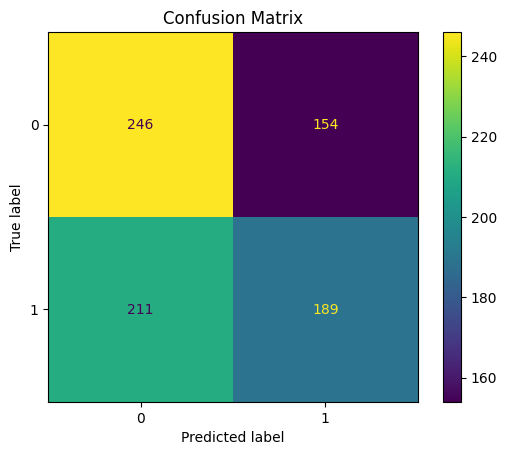

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(svm_model, X_test, y_test)
plt.title("Confusion Matrix")
plt.show()

In [9]:
image_path = "Dataset/test1/1.jpg"

img = cv2.imread(image_path)
img = cv2.resize(img, (64, 64))
img = img.flatten().reshape(1, -1)

prediction = svm_model.predict(img)

if prediction[0] == 0:
    print("Prediction: Cat")
else:
    print("Prediction: Dog")

Prediction: Cat
